# Movie Review Sentiment with a Text CNN

This notebook trains a 1D convolutional neural network (a "text CNN") to decide whether a movie
review is **positive** or **negative**. It handles plain reviews ("the movie was masterclass") and
tricky ones ("the movie was not so bad" uses *not* and *bad* but is positive).

**What you need in this folder:** `cnn_text_classification.csv` (columns `id`, `text`, `label`;
1 = positive, 0 = negative). Packages: `torch`, `pandas`, `numpy`, `matplotlib`, `scikit-learn`.

**What it produces:** an `artifacts/` folder (model weights, vocabulary, metrics) that the
Streamlit dashboard in `app.py` loads. Run all cells from top to bottom; the last cell lets you
type your own review.

| Step | What happens |
|---|---|
| 1 | Load and inspect the data |
| 2 | Turn text into token ids |
| 3 | Visualize the data |
| 4 | Split the data and add synthetic negation examples |
| 5 | Build the vocabulary and look at token ids |
| 6 | Define and train the CNN |
| 7 | Evaluate, including tricky sentences |
| 8 | See which words drove a prediction |
| 9 | Save everything for the app and try your own reviews |

In [14]:
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import HTML, display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Theme colours, shared by the notebook plots and the Streamlit app
OFFWHITE = "#F7F4EF"
PURPLE_DARK = "#2E1A47"
PURPLE = "#4B2A7B"
LAVENDER = "#E4DCEE"
RASPBERRY = "#A63D56"
MUTED = "#6B5B7F"

plt.rcParams.update({
    "figure.facecolor": OFFWHITE, "axes.facecolor": OFFWHITE, "savefig.facecolor": OFFWHITE,
    "axes.edgecolor": PURPLE_DARK, "axes.labelcolor": PURPLE_DARK, "text.color": PURPLE_DARK,
    "xtick.color": PURPLE_DARK, "ytick.color": PURPLE_DARK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 13,
    "font.size": 11, "figure.dpi": 110,
})

## 1. Load the data

In [15]:
DATA_PATH = "cnn_text_classification.csv"   # in Colab, upload the file first

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()), "| duplicate texts:", int(df["text"].duplicated().sum()))
print("Label counts:", df["label"].value_counts().to_dict(), "(1 = positive, 0 = negative)")
display(df.sample(8, random_state=SEED))

has_negation = df["text"].str.contains(r"\bnot\b|n't|\bnever\b", case=False)
print(f"\nReviews that contain a negation: {int(has_negation.sum())} of {len(df)}")
print("Distinct words in the whole file:", len({w for t in df['text'] for w in t.lower().split()}))

Shape: (600, 3)
Missing values: 0 | duplicate texts: 0
Label counts: {1: 300, 0: 300} (1 = positive, 0 = negative)


,id,text,label
110,111,The story was engaging and moving,1
419,420,The story was messy and messy,0
565,566,The story was brilliant and charming,1
77,78,The story was brilliant and engaging,1
181,182,The story was memorable and excellent,1
284,285,The movie was disappointing and frustrating,0
10,11,The movie was engaging and moving,1
469,470,The movie was delightful and memorable,1



Reviews that contain a negation: 12 of 600
Distinct words in the whole file: 80


**Worth knowing about this dataset.** Reviews are short (6 to 9 words), built from a small set of
phrases, and only a handful use negation. A model trained on this file alone will score very high on
a test split of the same file, but that does not mean it understands *not bad* or knows words such
as *good* or *masterclass*. Step 4 deals with that.

## 2. Turn text into token ids

A neural network needs numbers, not words. The helpers below:

1. **normalize** the text (lower-case, `wasn't` becomes `was not`),
2. **tokenize** it into words (the word *not* is deliberately kept),
3. **build a vocabulary** that gives every word an integer id (`0` = padding, `1` = unknown word),
4. **encode** a review as a fixed-length list of ids (cut or padded to 24 tokens).

In [16]:
import re
import html as html_lib
from collections import Counter

PAD, UNK = "<pad>", "<unk>"
MAX_LEN = 24  # every review is cut or padded to exactly this many tokens


def normalize(text):
    """Lower-case the text and expand contractions: wasn't -> was not."""
    text = text.replace("\u2019", "'").lower().strip()
    text = text.replace("can't", "can not").replace("cannot", "can not").replace("won't", "will not")
    return re.sub(r"n't\b", " not", text)


def tokenize(text):
    """Split a review into word tokens. The word 'not' is kept on purpose: it flips the meaning."""
    return re.findall(r"[a-z]+(?:'[a-z]+)?", normalize(text))


def build_vocab(texts, min_freq=1):
    """Map every word seen in `texts` to an integer id. 0 = padding, 1 = unknown word."""
    counts = Counter(tok for t in texts for tok in tokenize(t))
    words = sorted(w for w, c in counts.items() if c >= min_freq)
    return {w: i for i, w in enumerate([PAD, UNK] + words)}


def encode_tokens(tokens, stoi, max_len=MAX_LEN):
    """Tokens -> list of ids, padded with 0 (or cut) to max_len."""
    ids = [stoi.get(tok, stoi[UNK]) for tok in tokens][:max_len]
    return ids + [stoi[PAD]] * (max_len - len(ids))


def encode(text, stoi, max_len=MAX_LEN):
    """Review text -> list of token ids of length max_len."""
    return encode_tokens(tokenize(text), stoi, max_len)


def importance_chips_html(tokens, scores, threshold=0.03):
    """HTML chips: purple = pushes toward positive, raspberry = toward negative, lavender = little effect."""
    chips = []
    for tok, s in zip(tokens, scores):
        if s > threshold:
            bg, fg = PURPLE, "#FFFFFF"
        elif s < -threshold:
            bg, fg = RASPBERRY, "#FFFFFF"
        else:
            bg, fg = LAVENDER, PURPLE_DARK
        chips.append(
            "<span style='display:inline-block;text-align:center;margin:0 6px 10px 0;'>"
            f"<span style='display:block;background:{bg};color:{fg};padding:5px 12px;"
            f"border-radius:8px;font-size:16px;'>{html_lib.escape(tok)}</span>"
            f"<span style='display:block;font-size:12px;color:{MUTED};margin-top:3px;'>{s:+.2f}</span>"
            "</span>"
        )
    return (
        f"<div style='background:{OFFWHITE};padding:14px 14px 4px 14px;border-radius:10px;"
        f"line-height:1.4;'>{''.join(chips)}</div>"
    )

## 3. Visualize the data

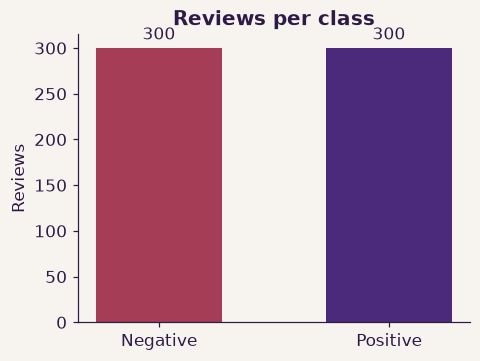

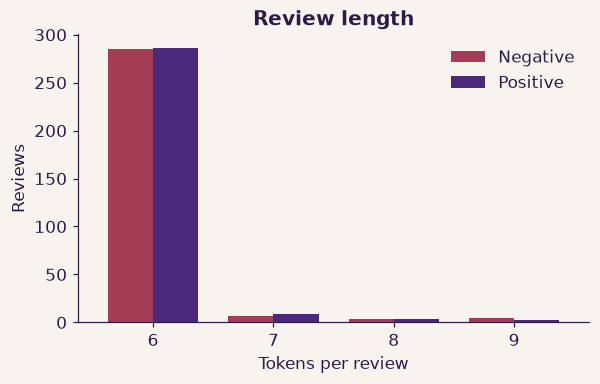

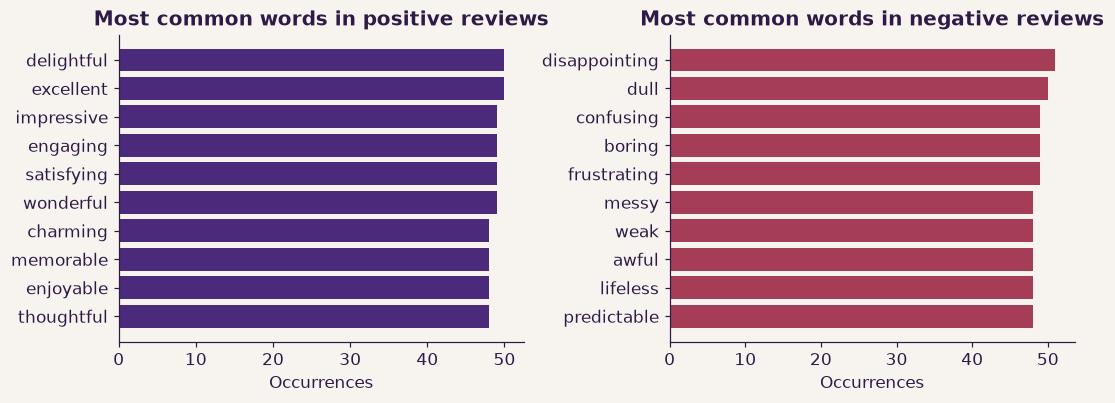

In [17]:
def plot_label_distribution(frame):
    counts = frame["label"].value_counts().reindex([0, 1], fill_value=0)
    fig, ax = plt.subplots(figsize=(4.6, 3.4))
    bars = ax.bar(["Negative", "Positive"], counts.values, color=[RASPBERRY, PURPLE], width=0.55)
    ax.bar_label(bars, padding=3)
    ax.set_ylabel("Reviews")
    ax.set_title("Reviews per class")
    plt.show()


def plot_length_distribution(frame):
    lengths = frame["text"].apply(lambda t: len(tokenize(t)))
    dist = pd.crosstab(lengths, frame["label"]).reindex(columns=[0, 1], fill_value=0)
    fig, ax = plt.subplots(figsize=(6, 3.4))
    dist.plot(kind="bar", ax=ax, color=[RASPBERRY, PURPLE], width=0.75)
    ax.legend(["Negative", "Positive"], frameon=False)
    ax.set_xlabel("Tokens per review")
    ax.set_ylabel("Reviews")
    ax.set_title("Review length")
    plt.xticks(rotation=0)
    plt.show()


DISPLAY_STOPWORDS = {"the", "was", "and", "but", "a", "an", "of", "it", "in", "at", "to", "is", "were", "had",
                     "all", "after", "first", "still", "movie", "story", "acting", "ending", "dialogue",
                     "direction", "performance", "soundtrack", "characters", "pacing"}


def plot_top_words(frame, top_n=10):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    for ax, (label, color, name) in zip(axes, [(1, PURPLE, "positive"), (0, RASPBERRY, "negative")]):
        counts = Counter(tok for t in frame.loc[frame["label"] == label, "text"] for tok in tokenize(t)
                         if tok not in DISPLAY_STOPWORDS)
        words, freq = zip(*counts.most_common(top_n))
        ax.barh(list(words)[::-1], list(freq)[::-1], color=color)
        ax.set_title(f"Most common words in {name} reviews")
        ax.set_xlabel("Occurrences")
    plt.tight_layout()
    plt.show()


plot_label_distribution(df)
plot_length_distribution(df)
plot_top_words(df)

## 4. Split the data and add synthetic negation examples

The original 600 reviews are split into train (70%), validation (15%) and test (15%) before
anything else happens, so the test set stays untouched.

Then, to teach the model things the CSV barely contains, we **generate extra training sentences** from
simple templates:

* everyday words such as *good, great, bad, terrible, masterclass, disaster*,
* negation: *not bad*, *not so bad*, *not good at all*, *never boring*, where the label is flipped,
* contrast: *weak at first but wonderful in the end*, where the last clause decides.

This augmentation is added to the **training and validation** sets only. Set `USE_AUGMENTATION = False`
to see how the model behaves without it. Sentences that appear in the test split or in the hand-written
check set below are removed from the synthetic data.

In [18]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
print(f"Original data -> train {len(train_df)}, validation {len(val_df)}, test {len(test_df)}")

# Hand-written sentences used to check the model after training (never used for training).
CHECK_SET = [
    ("Normal positive", "the movie was masterclass", 1),
    ("Normal positive", "the movie was good", 1),
    ("Normal positive", "the film was great", 1),
    ("Normal positive", "a wonderful and moving film", 1),
    ("Normal positive", "the acting was superb and the story was gripping", 1),
    ("Normal negative", "the movie was terrible", 0),
    ("Normal negative", "the acting was bad", 0),
    ("Normal negative", "the plot was tedious and shallow", 0),
    ("Normal negative", "a dull and lifeless film", 0),
    ("Normal negative", "the ending was a disaster", 0),
    ("Tricky positive", "the movie was not so bad", 1),
    ("Tricky positive", "it was not that bad", 1),
    ("Tricky positive", "the film was not boring at all", 1),
    ("Tricky positive", "the plot was never dull", 1),
    ("Tricky positive", "the script was not terrible", 1),
    ("Tricky negative", "the movie was not good", 0),
    ("Tricky negative", "the film was not great", 0),
    ("Tricky negative", "it was not very good", 0),
    ("Tricky negative", "the acting was not impressive", 0),
    ("Tricky negative", "the story was not enjoyable", 0),
    ("Contrast", "the plot was weak but the acting was brilliant", 1),
    ("Contrast", "the film started great but ended up boring", 0),
    ("Contrast", "the story was slow at first but wonderful in the end", 1),
    ("Contrast", "the acting was superb but the ending was a letdown", 0),
]

# Sentences made of words the model never sees in training. Expect these to be unreliable.
UNSEEN_WORDS_SET = [
    ("Unseen words", "the movie was a total snooze", 0),
    ("Unseen words", "absolutely loved every minute of it", 1),
    ("Unseen words", "i would gladly watch it again", 1),
    ("Unseen words", "it was kind of meh", 0),
]

Original data -> train 420, validation 90, test 90


In [ ]:
USE_AUGMENTATION = True
N_SYNTHETIC = 1200        # half positive, half negative
N_SYNTHETIC_VAL = 200     # part of the synthetic sentences kept for validation

import random

# Words that already appear in the CSV
POS_ORIGINAL = ["charming", "brilliant", "impressive", "memorable", "delightful", "enjoyable",
                "thoughtful", "excellent", "engaging", "moving", "satisfying", "wonderful"]
NEG_ORIGINAL = ["messy", "disappointing", "weak", "awful", "confusing", "lifeless", "boring",
                "dull", "unpleasant", "frustrating", "predictable", "forgettable"]

# Everyday sentiment words the CSV never uses
POS_EXTRA = ["good", "great", "fantastic", "amazing", "superb", "masterful", "outstanding",
             "terrific", "gripping", "stunning", "touching", "beautiful", "entertaining", "fun",
             "powerful", "captivating", "spectacular", "flawless", "fresh", "solid", "lovely"]
NEG_EXTRA = ["bad", "terrible", "horrible", "poor", "dreadful", "tedious", "mediocre", "pathetic",
             "painful", "annoying", "bland", "clumsy", "shallow", "stale", "unwatchable", "garbage"]
POS_NOUNS = ["masterclass", "triumph", "gem", "delight", "treat"]
NEG_NOUNS = ["disaster", "mess", "bore", "letdown", "flop"]

POS_WORDS = POS_ORIGINAL + POS_EXTRA
NEG_WORDS = NEG_ORIGINAL + NEG_EXTRA
POLARITY = {w: 1 for w in POS_WORDS + POS_NOUNS}
POLARITY.update({w: 0 for w in NEG_WORDS + NEG_NOUNS})

SUBJECTS = ["movie", "film", "story", "plot", "acting", "ending", "script", "dialogue",
            "direction", "soundtrack", "performance", "pacing"]
OPENERS = ["", "", "", "honestly ", "overall ", "i thought ", "to me "]
INTENSIFIERS = ["so", "very", "really", "quite", "truly", "incredibly"]
NEGATION_MODS = ["so", "very", "that", "too", "really"]


def carrier(rng):
    """A sentence frame with one slot, e.g. 'overall the film was {}'."""
    if rng.random() < 0.12:
        return "it was {}"
    return rng.choice(OPENERS) + "the " + rng.choice(SUBJECTS) + " was {}"


def pick(rng, positive):
    return rng.choice(POS_WORDS if positive else NEG_WORDS)


def make_plain(rng):                       # "the movie was good"
    w = rng.choice(POS_WORDS + NEG_WORDS)
    return carrier(rng).format(w), POLARITY[w]


def make_intensified(rng):                 # "the movie was really good"
    w = rng.choice(POS_WORDS + NEG_WORDS)
    return carrier(rng).format(rng.choice(INTENSIFIERS) + " " + w), POLARITY[w]


def make_negated(rng):                     # "the movie was not so bad"  -> positive
    w = rng.choice(POS_WORDS + NEG_WORDS)
    form = rng.choice(["not {w}", "not {w} at all", "not {m} {w}", "never {w}", "not {m} {w} at all"])
    pred = form.format(w=w, m=rng.choice(NEGATION_MODS))
    return carrier(rng).format(pred), 1 - POLARITY[w]


def make_noun(rng):                        # "the movie was a masterclass" / "not a disaster"
    n = rng.choice(POS_NOUNS + NEG_NOUNS)
    if rng.random() < 0.25:
        return carrier(rng).format("not a " + n), 1 - POLARITY[n]
    return carrier(rng).format("a " + n), POLARITY[n]


def make_but(rng):                         # the clause after "but" decides
    a1_pos = rng.random() < 0.5
    a2_pos = (not a1_pos) if rng.random() < 0.8 else a1_pos
    a1, a2 = pick(rng, a1_pos), pick(rng, a2_pos)
    s1, s2 = rng.sample(SUBJECTS, 2)
    return f"the {s1} was {a1} but the {s2} was {a2}", int(a2_pos)


def make_time(rng):                        # "weak at first but wonderful in the end"
    a1_pos = rng.random() < 0.5
    a2_pos = (not a1_pos) if rng.random() < 0.85 else a1_pos
    a1, a2 = pick(rng, a1_pos), pick(rng, a2_pos)
    s = rng.choice(SUBJECTS)
    text = rng.choice([f"the {s} was {a1} at first but {a2} in the end",
                       f"the {s} started {a1} but ended up {a2}"])
    return text, int(a2_pos)


def make_pair(rng):                        # "the movie was good and fun"
    positive = rng.random() < 0.5
    a, b = rng.sample(POS_WORDS if positive else NEG_WORDS, 2)
    return carrier(rng).format(f"{a} and {b}"), int(positive)


PATTERNS = [(make_plain, 15), (make_intensified, 10), (make_negated, 30), (make_noun, 8),
            (make_but, 14), (make_time, 8), (make_pair, 15)]


def generate_augmented(n_total, seed, exclude=()):
    """Create balanced synthetic reviews, skipping any sentence listed in `exclude`."""
    rng = random.Random(seed)
    banned = {" ".join(tokenize(t)) for t in exclude}
    makers, weights = zip(*PATTERNS)
    per_class = n_total // 2
    counts = {0: 0, 1: 0}
    seen, rows = set(), []
    for _ in range(300_000):
        if counts[0] >= per_class and counts[1] >= per_class:
            break
        text, label = rng.choices(makers, weights)[0](rng)
        key = " ".join(tokenize(text))
        if key in banned or key in seen or counts[label] >= per_class:
            continue
        seen.add(key)
        counts[label] += 1
        rows.append({"text": text, "label": label})
    rng.shuffle(rows)
    return pd.DataFrame(rows)


if USE_AUGMENTATION:
    exclude = list(val_df["text"]) + list(test_df["text"]) + [t for _, t, _ in CHECK_SET + UNSEEN_WORDS_SET]
    synthetic_df = generate_augmented(N_SYNTHETIC, SEED, exclude=exclude)
    synth_train, synth_val = train_test_split(synthetic_df, test_size=N_SYNTHETIC_VAL,
                                              stratify=synthetic_df["label"], random_state=SEED)
    print("Synthetic examples:", len(synth_train), "train,", len(synth_val), "validation")
    display(synth_train.sample(10, random_state=SEED))
else:
    synth_train = synth_val = pd.DataFrame({"text": [], "label": []})
    print("Augmentation is off.")

fit_train_df = pd.concat([train_df[["text", "label"]], synth_train], ignore_index=True)
fit_val_df = pd.concat([val_df[["text", "label"]], synth_val], ignore_index=True)
print(f"Training on {len(fit_train_df)} reviews, validating on {len(fit_val_df)}, testing on {len(test_df)}")

Synthetic examples: 1000 train, 200 validation


,text,label
698,overall the soundtrack was not that awful at all,1
582,the story was not disappointing at all,1
228,honestly the ending was good,1
936,honestly the script was never confusing,1
30,it was not dull,1
846,the acting was excellent at first but shallow ...,0
421,overall the performance was never engaging,0
1127,it was a treat,1
1018,the performance started bad but ended up amazing,1
1197,the direction was poor but the movie was charming,1


Training on 1420 reviews, validating on 290, testing on 90


## 5. Build the vocabulary and look at token ids

The vocabulary is built from the **training** texts only. Any word the model has not seen becomes `<unk>` (id 1).

In [7]:
stoi = build_vocab(fit_train_df["text"])            # word -> id
itos = {i: w for w, i in stoi.items()}               # id -> word
PAD_ID, UNK_ID = stoi[PAD], stoi[UNK]
print("Vocabulary size:", len(stoi))


def show_token_ids(text):
    tokens = tokenize(text)
    table = pd.DataFrame({
        "position": range(1, len(tokens) + 1),
        "token": tokens,
        "id": [stoi.get(t, UNK_ID) for t in tokens],
        "known": ["yes" if t in stoi else "no (unk)" for t in tokens],
    })
    display(table.set_index("position"))
    print(f"Padded to {MAX_LEN}:", encode(text, stoi))


show_token_ids("The movie wasn't so bad")

Vocabulary size: 142


,token,id,known
position,,,
1,the,122,yes
2,movie,79,yes
3,was,136,yes
4,not,82,yes
5,so,105,yes
6,bad,11,yes


Padded to 24: [122, 79, 136, 82, 105, 11, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## 6. The CNN

How a review flows through the network:

1. **Embedding**: every token id becomes a 64-number vector the model learns.
2. **Convolutions** with window sizes 2, 3 and 4 slide over the sequence. Each filter acts as a small
   detector for a phrase pattern; a width-2 filter can learn that the pair *not bad* is positive.
3. **Max pooling over time** keeps each filter's strongest match anywhere in the review.
4. **Dropout and a linear layer** turn the pooled features into one score; above 0 means positive.

During training, a few random words are replaced with `<unk>` ("word dropout", never the words *not*
or *never*). This trains the `<unk>` vector to be neutral, so unseen words at prediction time do not
push the result in a random direction.

In [9]:
import copy

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)


def to_tensors(frame):
    x = torch.tensor([encode(t, stoi) for t in frame["text"]], dtype=torch.long)
    y = torch.tensor(frame["label"].astype("float32").values)
    return x, y


X_train, y_train = to_tensors(fit_train_df)
X_val, y_val = to_tensors(fit_val_df)
print("Train tensor:", tuple(X_train.shape), "| Validation tensor:", tuple(X_val.shape))

BATCH_SIZE = 32
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=64)

Device: cpu
Train tensor: (1420, 24) | Validation tensor: (290, 24)


In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class TextCNN(nn.Module):
    """Embedding -> parallel 1D convolutions (n-gram detectors) -> max over time -> linear."""

    def __init__(self, vocab_size, embed_dim=64, num_filters=64, kernel_sizes=(2, 3, 4), dropout=0.4, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.convs = nn.ModuleList([nn.Conv1d(embed_dim, num_filters, k) for k in kernel_sizes])
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(num_filters * len(kernel_sizes), 1)

    def forward(self, x):                              # x: (batch, seq_len) of token ids
        emb = self.embedding(x).transpose(1, 2)        # (batch, embed_dim, seq_len)
        pooled = [F.relu(conv(emb)).max(dim=2).values for conv in self.convs]
        features = self.dropout(torch.cat(pooled, dim=1))
        return self.fc(features).squeeze(1)            # one logit per review: > 0 means positive


def probs_from_token_lists(model, stoi, token_lists, device="cpu"):
    """Probability of 'positive' for each list of tokens."""
    model.eval()
    ids = [encode_tokens(tokens, stoi) for tokens in token_lists]
    x = torch.tensor(ids, dtype=torch.long, device=device)
    with torch.no_grad():
        return torch.sigmoid(model(x)).cpu().tolist()


def predict_text(model, stoi, text, device="cpu"):
    """Predict one review. Returns None when the text has no readable words."""
    tokens = tokenize(text)
    if not tokens:
        return None
    p = probs_from_token_lists(model, stoi, [tokens], device)[0]
    return {
        "label": "Positive" if p >= 0.5 else "Negative",
        "prob_positive": p,
        "confidence": max(p, 1 - p),
        "tokens": tokens,
        "unknown_words": [t for t in tokens if t not in stoi],
        "truncated": len(tokens) > MAX_LEN,
    }


def word_importance(model, stoi, text, device="cpu"):
    """Remove each word in turn and measure how P(positive) changes.
    A positive score means the word pushes the review toward positive."""
    tokens = tokenize(text)[:MAX_LEN]
    variants = [tokens] + [tokens[:i] + tokens[i + 1:] for i in range(len(tokens))]
    probs = probs_from_token_lists(model, stoi, variants, device)
    base = probs[0]
    return tokens, [base - p for p in probs[1:]], base


CONFIG = {"vocab_size": len(stoi), "embed_dim": 64, "num_filters": 64, "kernel_sizes": [2, 3, 4],
          "dropout": 0.4, "max_len": MAX_LEN}
model = TextCNN(CONFIG["vocab_size"], CONFIG["embed_dim"], CONFIG["num_filters"],
                tuple(CONFIG["kernel_sizes"]), CONFIG["dropout"]).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"Trainable parameters: {n_params:,}")

TextCNN(
  (embedding): Embedding(142, 64, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(64, 64, kernel_size=(2,), stride=(1,))
    (1): Conv1d(64, 64, kernel_size=(3,), stride=(1,))
    (2): Conv1d(64, 64, kernel_size=(4,), stride=(1,))
  )
  (dropout): Dropout(p=0.4, inplace=False)
  (fc): Linear(in_features=192, out_features=1, bias=True)
)
Trainable parameters: 46,337


## 7. Train

Adam optimizer, binary cross-entropy loss, and **early stopping**: training ends when the validation loss has
not improved for 8 epochs, and the best weights are restored.

In [11]:
EPOCHS, PATIENCE, LEARNING_RATE, WORD_DROPOUT = 40, 8, 1e-3, 0.08
KEEP_IDS = torch.tensor([stoi[w] for w in ("not", "never") if w in stoi], device=DEVICE)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)


def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if train and WORD_DROPOUT > 0:
                drop = (torch.rand_like(xb, dtype=torch.float) < WORD_DROPOUT) & (xb != PAD_ID)
                drop = drop & ~torch.isin(xb, KEEP_IDS)
                xb = xb.masked_fill(drop, UNK_ID)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += ((logits > 0).float() == yb).sum().item()
            count += len(yb)
    return total_loss / count, correct / count


history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss, best_state, bad_epochs = float("inf"), None, 0

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)
    for key, value in zip(history, (tr_loss, va_loss, tr_acc, va_acc)):
        history[key].append(value)
    if va_loss < best_val_loss - 1e-4:
        best_val_loss, best_state, bad_epochs = va_loss, copy.deepcopy(model.state_dict()), 0
    else:
        bad_epochs += 1
    if epoch == 1 or epoch % 5 == 0:
        print(f"epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | val loss {va_loss:.4f} acc {va_acc:.3f}")
    if bad_epochs >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

model.load_state_dict(best_state)
epochs_trained = len(history["train_loss"])
print(f"Restored best weights (validation loss {best_val_loss:.4f}) after {epochs_trained} epochs")

epoch  1 | train loss 0.6650 acc 0.584 | val loss 0.5806 acc 0.700
epoch  5 | train loss 0.3504 acc 0.846 | val loss 0.3591 acc 0.831
epoch 10 | train loss 0.1480 acc 0.952 | val loss 0.1531 acc 0.952
epoch 15 | train loss 0.0836 acc 0.973 | val loss 0.0714 acc 0.979
epoch 20 | train loss 0.0590 acc 0.976 | val loss 0.0439 acc 0.986
epoch 25 | train loss 0.0548 acc 0.981 | val loss 0.0325 acc 0.990
epoch 30 | train loss 0.0568 acc 0.980 | val loss 0.0177 acc 0.997
epoch 35 | train loss 0.0381 acc 0.983 | val loss 0.0264 acc 0.993
epoch 40 | train loss 0.0508 acc 0.975 | val loss 0.0114 acc 1.000
Restored best weights (validation loss 0.0105) after 40 epochs


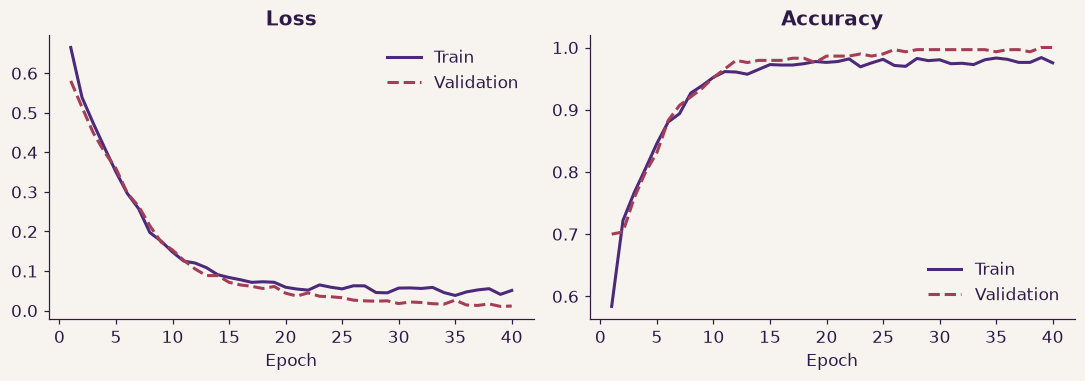

In [12]:
def plot_training_curves(hist):
    epochs = range(1, len(hist["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    for ax, key, title in zip(axes, ("loss", "acc"), ("Loss", "Accuracy")):
        ax.plot(epochs, hist[f"train_{key}"], color=PURPLE, linewidth=2, label="Train")
        ax.plot(epochs, hist[f"val_{key}"], color=RASPBERRY, linewidth=2, linestyle="--", label="Validation")
        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()


plot_training_curves(history)

## 8. Evaluate

### On the held-out test split
These are 90 reviews from the original CSV that the model never trained on. Because the file is so
repetitive, expect a very high score; it mainly confirms nothing is broken.

Test accuracy: 1.000 | F1: 1.000

              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        45
    Positive       1.00      1.00      1.00        45

    accuracy                           1.00        90
   macro avg       1.00      1.00      1.00        90
weighted avg       1.00      1.00      1.00        90



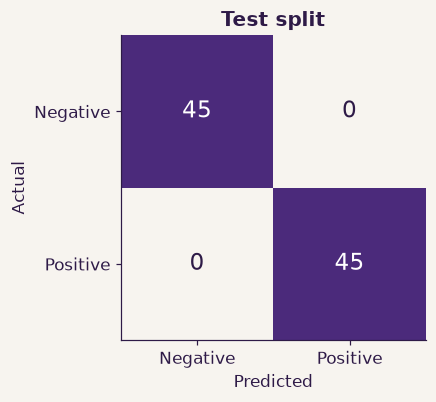

In [13]:
def plot_confusion(cm, title):
    cmap = LinearSegmentedColormap.from_list("offwhite_purple", [OFFWHITE, PURPLE])
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    ax.imshow(cm, cmap=cmap)
    ax.set_xticks([0, 1], ["Negative", "Positive"])
    ax.set_yticks([0, 1], ["Negative", "Positive"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=15,
                    color="white" if cm[i, j] > cm.max() / 2 else PURPLE_DARK)
    plt.show()


test_probs = np.array(probs_from_token_lists(model, stoi, [tokenize(t) for t in test_df["text"]], DEVICE))
test_pred = (test_probs >= 0.5).astype(int)
test_acc = accuracy_score(test_df["label"], test_pred)
test_f1 = f1_score(test_df["label"], test_pred)
print(f"Test accuracy: {test_acc:.3f} | F1: {test_f1:.3f}\n")
print(classification_report(test_df["label"], test_pred, target_names=["Negative", "Positive"]))
plot_confusion(confusion_matrix(test_df["label"], test_pred), "Test split")

### On tricky and unusual sentences
This is the more honest check. The sentences were written by hand and removed from the synthetic training
data, but many follow the same patterns the templates teach (for example *the movie was not so bad*), so
this shows that the model **learned the negation patterns**, not that it understands arbitrary English.
The "Unseen words" group uses vocabulary the model has never seen, so mistakes there are expected.

In [14]:
def evaluate_sentences(items):
    probs = probs_from_token_lists(model, stoi, [tokenize(t) for _, t, _ in items], DEVICE)
    rows = []
    for (group, text, expected), p in zip(items, probs):
        predicted = int(p >= 0.5)
        rows.append({"group": group, "review": text, "expected": "Positive" if expected else "Negative",
                     "predicted": "Positive" if predicted else "Negative", "P(positive)": round(p, 3),
                     "result": "OK" if predicted == expected else "WRONG"})
    return pd.DataFrame(rows)


check_results = evaluate_sentences(CHECK_SET)
display(check_results)
check_by_group = check_results.groupby("group")["result"].apply(lambda s: (s == "OK").mean())
check_acc = (check_results["result"] == "OK").mean()
print(check_by_group.round(3).to_string())
print(f"\nHand-written check set accuracy: {check_acc:.3f} ({len(check_results)} sentences)")

unseen_results = evaluate_sentences(UNSEEN_WORDS_SET)
display(unseen_results)
unseen_acc = (unseen_results["result"] == "OK").mean()

,group,review,expected,predicted,P(positive),result
0,Normal positive,the movie was masterclass,Positive,Positive,0.992,OK
1,Normal positive,the movie was good,Positive,Positive,0.997,OK
2,Normal positive,the film was great,Positive,Positive,0.997,OK
3,Normal positive,a wonderful and moving film,Positive,Positive,0.998,OK
4,Normal positive,the acting was superb and the story was gripping,Positive,Positive,0.999,OK
5,Normal negative,the movie was terrible,Negative,Negative,0.002,OK
6,Normal negative,the acting was bad,Negative,Negative,0.002,OK
7,Normal negative,the plot was tedious and shallow,Negative,Negative,0.000,OK
8,Normal negative,a dull and lifeless film,Negative,Negative,0.001,OK
9,Normal negative,the ending was a disaster,Negative,Negative,0.011,OK


group
Contrast           1.0
Normal negative    1.0
Normal positive    1.0
Tricky negative    1.0
Tricky positive    1.0

Hand-written check set accuracy: 1.000 (24 sentences)


,group,review,expected,predicted,P(positive),result
0,Unseen words,the movie was a total snooze,Negative,Negative,0.230,OK
1,Unseen words,absolutely loved every minute of it,Positive,Positive,0.598,OK
2,Unseen words,i would gladly watch it again,Positive,Positive,0.671,OK
3,Unseen words,it was kind of meh,Negative,Negative,0.472,OK


## 9. See which words drove a prediction

`word_importance` removes each word in turn and measures how much the probability of *positive* changes.
Purple pushes toward positive, raspberry toward negative. In *the movie was not so bad*, you should see
**not** and **bad** acting together as a pair rather than **bad** simply pulling the score down.

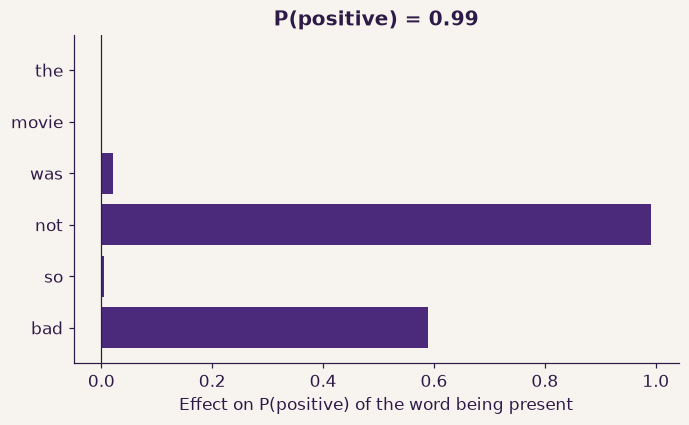

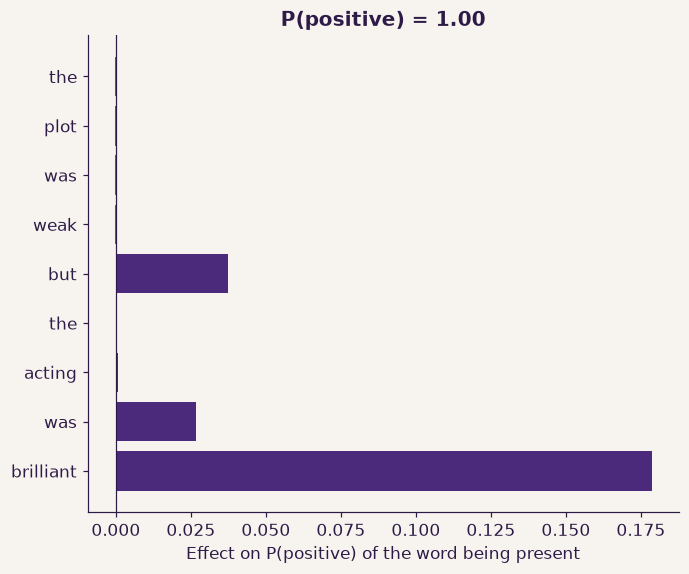

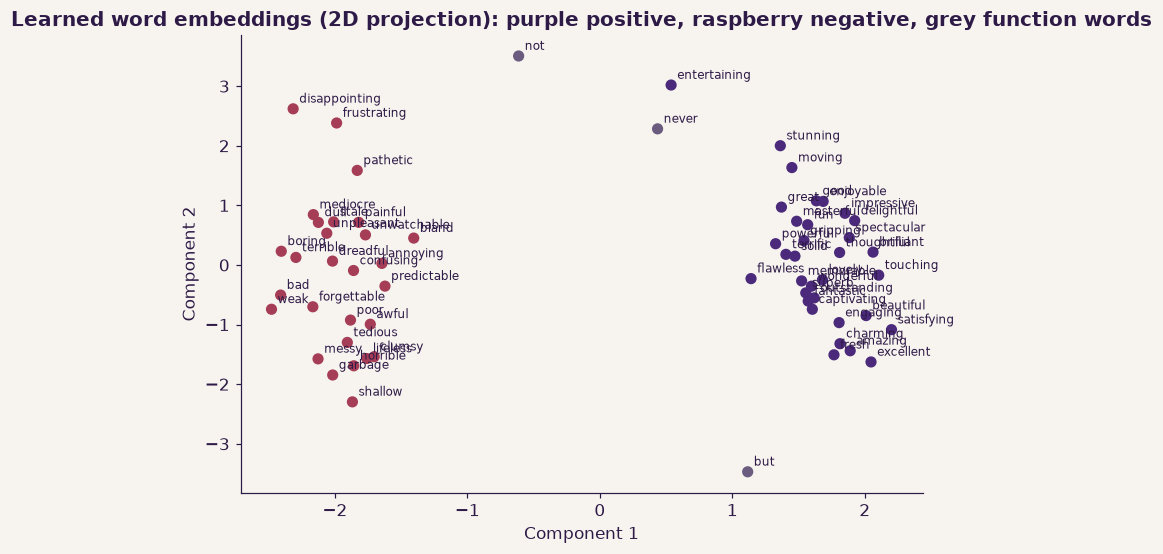

In [15]:
def plot_word_importance(text):
    tokens, scores, base = word_importance(model, stoi, text, DEVICE)
    fig, ax = plt.subplots(figsize=(6.4, 0.45 * len(tokens) + 1.3))
    ax.barh(range(len(tokens)), scores, color=[PURPLE if s >= 0 else RASPBERRY for s in scores])
    ax.set_yticks(range(len(tokens)), tokens)
    ax.invert_yaxis()
    ax.axvline(0, color=PURPLE_DARK, linewidth=0.8)
    ax.set_xlabel("Effect on P(positive) of the word being present")
    ax.set_title(f"P(positive) = {base:.2f}")
    plt.tight_layout()
    plt.show()
    display(HTML(importance_chips_html(tokens, scores)))


def plot_embeddings():
    from sklearn.decomposition import PCA
    words = [w for w in POS_WORDS + NEG_WORDS + ["not", "never", "but"] if w in stoi]
    vectors = model.embedding.weight.detach().cpu().numpy()[[stoi[w] for w in words]]
    coords = PCA(n_components=2, random_state=SEED).fit_transform(vectors)
    colors = [PURPLE if w in POS_WORDS else RASPBERRY if w in NEG_WORDS else MUTED for w in words]
    fig, ax = plt.subplots(figsize=(8, 5.4))
    ax.scatter(coords[:, 0], coords[:, 1], c=colors, s=40)
    for (x, y), w in zip(coords, words):
        ax.annotate(w, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=8, color=PURPLE_DARK)
    ax.set_title("Learned word embeddings (2D projection): purple positive, raspberry negative, grey function words")
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    plt.show()


plot_word_importance("the movie was not so bad")
plot_word_importance("the plot was weak but the acting was brilliant")
plot_embeddings()

## 10. Save for the app

In [16]:
ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

torch.save({"state_dict": {k: v.cpu() for k, v in model.state_dict().items()}, "config": CONFIG},
           ARTIFACT_DIR / "cnn_sentiment.pt")
(ARTIFACT_DIR / "vocab.json").write_text(json.dumps(stoi, indent=0))
metrics = {
    "test_accuracy": float(test_acc),
    "test_f1": float(test_f1),
    "check_set_accuracy": float(check_acc),
    "check_set_size": int(len(check_results)),
    "check_set_by_group": {k: float(v) for k, v in check_by_group.items()},
    "unseen_words_accuracy": float(unseen_acc),
    "parameters": int(n_params),
    "vocab_size": int(len(stoi)),
    "train_reviews_original": int(len(train_df)),
    "train_reviews_synthetic": int(len(synth_train)),
    "epochs_trained": int(epochs_trained),
    "augmentation": bool(USE_AUGMENTATION),
}
(ARTIFACT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))
print("Saved:", sorted(p.name for p in ARTIFACT_DIR.iterdir()))

Saved: ['cnn_sentiment.pt', 'metrics.json', 'vocab.json']


## 11. Try your own review

Run the cell below, type a review and press Enter. Leave the box empty to stop.
Examples to try: *the movie was masterclass*, *the movie was good*, *the movie was not so bad*,
*the film was not good at all*, *the plot was weak but the acting was brilliant*.

In [17]:
def predict_review(text):
    result = predict_text(model, stoi, text, DEVICE)
    if result is None:
        print("No readable words found. Try a full sentence.")
        return
    print(f"Review     : {text}")
    print(f"Sentiment  : {result['label'].upper()}  (confidence {result['confidence']:.1%}, "
          f"P(positive) = {result['prob_positive']:.3f})")
    if result["unknown_words"]:
        print("Unseen words (ignored by the model):", ", ".join(result["unknown_words"]))
    tokens, scores, _ = word_importance(model, stoi, text, DEVICE)
    display(HTML(importance_chips_html(tokens, scores)))


for sample in ["the movie was masterclass", "the movie was good", "the movie was not so bad", "the movie was not good"]:
    predict_review(sample)
    print("-" * 60)

while True:
    try:
        review = input("Type a movie review (press Enter to stop): ").strip()
    except Exception:
        print("Interactive input is not available here. Call predict_review('your text') instead.")
        break
    if not review:
        print("Stopped.")
        break
    predict_review(review)
    print("-" * 60)

Review     : the movie was masterclass
Sentiment  : POSITIVE  (confidence 99.2%, P(positive) = 0.992)


------------------------------------------------------------
Review     : the movie was good
Sentiment  : POSITIVE  (confidence 99.7%, P(positive) = 0.997)


------------------------------------------------------------
Review     : the movie was not so bad
Sentiment  : POSITIVE  (confidence 99.4%, P(positive) = 0.994)


------------------------------------------------------------
Review     : the movie was not good
Sentiment  : NEGATIVE  (confidence 95.6%, P(positive) = 0.044)


------------------------------------------------------------
Review     : the movie was not so good
Sentiment  : NEGATIVE  (confidence 98.0%, P(positive) = 0.020)


------------------------------------------------------------
Stopped.
